# Bangla Sentence Classification — Five Model Comparison

This notebook trains and evaluates **five models** on the same Bangla dataset and the same train/validation/test split.

**Models**
1. Random Forest (TF-IDF word + character features)
2. BanglaBERT (`csebuetnlp/banglabert`)
3. XLM-RoBERTa Base (`FacebookAI/xlm-roberta-base`)
4. MuRIL Base (`google/muril-base-cased`)
5. IndicBERT v2 (`ai4bharat/IndicBERTv2-MLM-only`)

**Tasks:** Function, Tense, Structure.

## Before running
1. Open this notebook in Google Colab.
2. Select **Runtime → Change runtime type → T4 GPU**.
3. Run cells from top to bottom.
4. Upload your latest corrected Excel dataset when prompted.

The four transformer models train one after another. This may take a while on a free Colab T4 GPU. Do not close the runtime while training.


In [1]:
!pip -q install transformers accelerate scikit-learn pandas seaborn joblib openpyxl
from google.colab import files
uploaded = files.upload()


Saving Bangla-Sentence-Classification.xlsx to Bangla-Sentence-Classification.xlsx


In [2]:
import os, gc, json, random, shutil
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix
)
from sklearn.preprocessing import LabelEncoder
from torch.utils.data import Dataset, DataLoader
from transformers import AutoTokenizer, AutoModel, get_linear_schedule_with_warmup

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
if device.type != "cuda":
    print("WARNING: GPU not detected. Transformer training will be much slower.")


Device: cuda


In [3]:
# Select the uploaded Excel file automatically.
import os

# Fallback list of known/possible uploaded filenames
possible_names = ["Bangla_Dataset_Lexical_Bias_Fixed_v4.xlsx"]

try:
    xlsx_files = [f for f in uploaded.keys() if f.lower().endswith((".xlsx", ".xls"))]
except NameError:
    xlsx_files = [f for f in os.listdir(".") if f.lower().endswith((".xlsx", ".xls"))]

# Force check for the known saved name in the directory if list is empty
if not xlsx_files:
    for name in possible_names:
        if os.path.exists(name):
            xlsx_files.append(name)

if not xlsx_files:
    raise FileNotFoundError("Please upload your corrected .xlsx dataset.")

FILE = xlsx_files[0]
print("Using:", FILE)

df = pd.read_excel(FILE)
df.columns = df.columns.astype(str).str.strip()

TASKS = ["Function", "Tense", "Structure"]
required = ["Sentence"] + TASKS
missing = [c for c in required if c not in df.columns]
if missing:
    raise ValueError(f"Missing required columns: {missing}")

df = df[required].copy()
df = df.dropna(subset=required).copy()
df["Sentence"] = df["Sentence"].astype(str).str.strip()
for task in TASKS:
    df[task] = df[task].astype(str).str.strip()

df = df[df["Sentence"].ne("")].reset_index(drop=True)

print("Rows:", len(df))
print("\nLabel distributions:")
for task in TASKS:
    print(f"\n{task}")
    print(df[task].value_counts())
display(df.head())

Using: Bangla-Sentence-Classification.xlsx
Rows: 2000

Label distributions:

Function
Function
Interrogative    500
Exclamatory      500
Declarative      500
Imperative       500
Name: count, dtype: int64

Tense
Tense
present    778
future     658
past       564
Name: count, dtype: int64

Structure
Structure
complex     737
compound    654
simple      609
Name: count, dtype: int64


,Sentence,Function,Tense,Structure
0,"সে কেন মিটিং মিস করবে, এবং কে বাকিদের জানাবে?",Interrogative,future,compound
1,"দারুণ, আগামীকালের দৃশ্যটি হবে অপূর্ব!",Exclamatory,future,simple
2,তারা পার্টিতে কখন পৌঁছেছিল যা সন্ধ্যা ৬টায় শু...,Interrogative,past,complex
3,"আমি একটি রিপোর্ট লিখব, এবং ক্লাস শুরু হওয়ার আ...",Declarative,future,compound
4,আমরা স্কুলের পরে একসাথে পড়ি।,Declarative,present,simple


## 1. Create one shared data split

All five models use these exact same rows for training, validation, and testing. This makes the comparison fairer.

Split: **80% train / 10% validation / 10% test**. Stratification uses Function labels; check the printed distributions to confirm the other two tasks also have all expected labels in each split.


In [4]:
# First split: 80% train, 20% temporary
train_df, temp_df = train_test_split(
    df, test_size=0.20, random_state=SEED, stratify=df["Function"]
)
# Second split: 10% validation, 10% test overall
val_df, test_df = train_test_split(
    temp_df, test_size=0.50, random_state=SEED, stratify=temp_df["Function"]
)

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print("Train:", len(train_df), "Validation:", len(val_df), "Test:", len(test_df))
for split_name, part in [("TRAIN", train_df), ("VALIDATION", val_df), ("TEST", test_df)]:
    print(f"\n{split_name}")
    for task in TASKS:
        print(task, part[task].value_counts().to_dict())


Train: 1600 Validation: 200 Test: 200

TRAIN
Function {'Exclamatory': 400, 'Declarative': 400, 'Interrogative': 400, 'Imperative': 400}
Tense {'present': 627, 'future': 515, 'past': 458}
Structure {'complex': 583, 'compound': 525, 'simple': 492}

VALIDATION
Function {'Exclamatory': 50, 'Interrogative': 50, 'Imperative': 50, 'Declarative': 50}
Tense {'present': 77, 'future': 68, 'past': 55}
Structure {'complex': 73, 'compound': 68, 'simple': 59}

TEST
Function {'Interrogative': 50, 'Declarative': 50, 'Imperative': 50, 'Exclamatory': 50}
Tense {'future': 75, 'present': 74, 'past': 51}
Structure {'complex': 81, 'compound': 61, 'simple': 58}


## 2. Random Forest

Random Forest uses TF-IDF word and character features. A separate classifier is trained for each task, using the shared split.


\n========== Random Forest — Function ==========
               precision    recall  f1-score   support

  Declarative       1.00      1.00      1.00        50
  Exclamatory       0.98      1.00      0.99        50
   Imperative       1.00      1.00      1.00        50
Interrogative       1.00      0.98      0.99        50

     accuracy                           0.99       200
    macro avg       1.00      0.99      0.99       200
 weighted avg       1.00      0.99      0.99       200



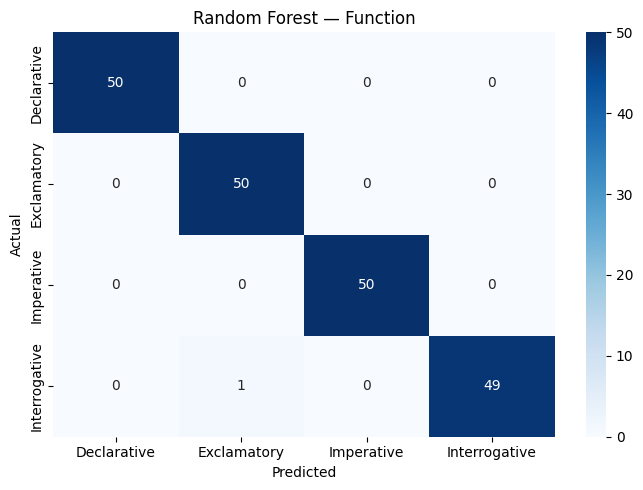

\n========== Random Forest — Tense ==========
              precision    recall  f1-score   support

      future       1.00      0.96      0.98        75
        past       0.98      0.90      0.94        51
     present       0.90      0.99      0.94        74

    accuracy                           0.95       200
   macro avg       0.96      0.95      0.95       200
weighted avg       0.96      0.95      0.96       200



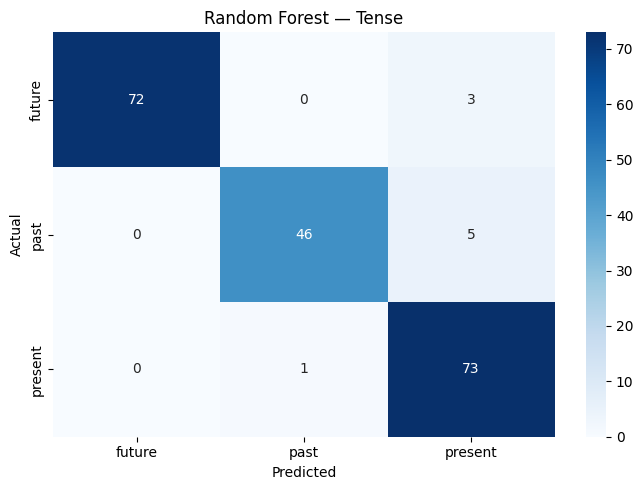

\n========== Random Forest — Structure ==========
              precision    recall  f1-score   support

     complex       0.97      0.95      0.96        81
    compound       0.91      0.98      0.94        61
      simple       1.00      0.95      0.97        58

    accuracy                           0.96       200
   macro avg       0.96      0.96      0.96       200
weighted avg       0.96      0.96      0.96       200



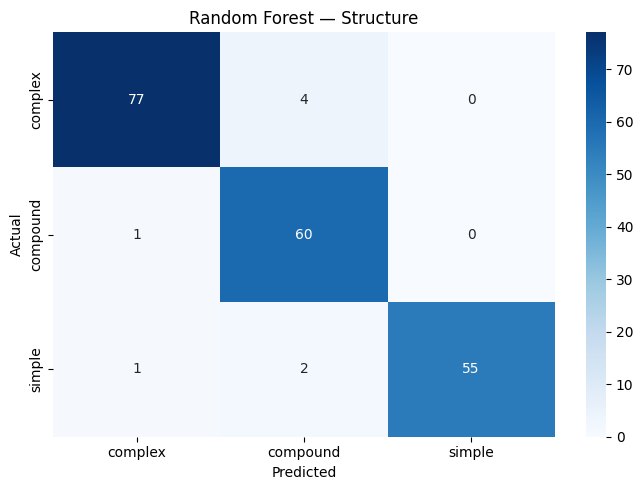

In [5]:
def make_rf_pipeline():
    features = FeatureUnion([
        ("word", TfidfVectorizer(
            analyzer="word", ngram_range=(1, 2), sublinear_tf=True,
            token_pattern=r"[^\\s,।?!;:]+", max_features=60000
        )),
        ("char", TfidfVectorizer(
            analyzer="char_wb", ngram_range=(2, 5), sublinear_tf=True,
            max_features=80000
        ))
    ])
    clf = RandomForestClassifier(
        n_estimators=300, class_weight="balanced",
        random_state=SEED, n_jobs=-1
    )
    return Pipeline([("features", features), ("classifier", clf)])

all_results = []
rf_models = {}

for task in TASKS:
    print(f"\\n========== Random Forest — {task} ==========")
    rf = make_rf_pipeline()
    rf.fit(train_df["Sentence"], train_df[task])
    pred = rf.predict(test_df["Sentence"])
    true = test_df[task]

    print(classification_report(true, pred, zero_division=0))
    result = {
        "Model": "Random Forest", "Task": task,
        "Accuracy": accuracy_score(true, pred),
        "Precision_macro": precision_score(true, pred, average="macro", zero_division=0),
        "Recall_macro": recall_score(true, pred, average="macro", zero_division=0),
        "Macro_F1": f1_score(true, pred, average="macro", zero_division=0)
    }
    all_results.append(result)
    rf_models[task] = rf
    joblib.dump(rf, f"random_forest_{task.lower()}.joblib")

    labels = sorted(df[task].unique())
    cm = confusion_matrix(true, pred, labels=labels)
    plt.figure(figsize=(7, 5))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=labels, yticklabels=labels)
    plt.title(f"Random Forest — {task}")
    plt.xlabel("Predicted"); plt.ylabel("Actual")
    plt.tight_layout()
    plt.savefig(f"cm_random_forest_{task.lower()}.png", dpi=160)
    plt.show()



## 3. Transformer models

Each transformer uses one shared encoder with three classification heads (Function, Tense, Structure). The best checkpoint is selected using the **average validation Macro-F1 across the three tasks**.

Default settings are conservative for a Colab T4: max length 96, batch size 8, gradient accumulation 2, and up to 3 epochs. If you get CUDA out-of-memory, reduce `BATCH_SIZE` to 4 or `MAX_LEN` to 64.


In [6]:
MODEL_CONFIGS = {
    "BanglaBERT": "csebuetnlp/banglabert",
    "XLM-RoBERTa": "FacebookAI/xlm-roberta-base",
    "MuRIL": "google/muril-base-cased",
    "IndicBERTv2": "ai4bharat/IndicBERTv2-MLM-only"
}

MAX_LEN = 96
BATCH_SIZE = 8
GRAD_ACCUM = 2
EPOCHS = 3
LEARNING_RATE = 2e-5
PATIENCE = 2

# Encode each task's labels once so all transformer models use identical label IDs.
label_encoders = {}
label_maps = {}
for task in TASKS:
    le = LabelEncoder()
    le.fit(df[task])
    label_encoders[task] = le
    label_maps[task] = {str(label): int(i) for i, label in enumerate(le.classes_)}

with open("label_maps.json", "w", encoding="utf-8") as f:
    json.dump(label_maps, f, ensure_ascii=False, indent=2)

class BanglaMultiTaskDataset(Dataset):
    def __init__(self, frame, tokenizer):
        self.frame = frame.reset_index(drop=True)
        self.tokenizer = tokenizer

    def __len__(self):
        return len(self.frame)

    def __getitem__(self, idx):
        row = self.frame.iloc[idx]
        enc = self.tokenizer(
            row["Sentence"], max_length=MAX_LEN, truncation=True,
            padding="max_length", return_tensors="pt"
        )
        item = {
            "input_ids": enc["input_ids"].squeeze(0),
            "attention_mask": enc["attention_mask"].squeeze(0)
        }
        for task in TASKS:
            item[task] = torch.tensor(
                label_encoders[task].transform([row[task]])[0],
                dtype=torch.long
            )
        return item

class MultiTaskTransformer(nn.Module):
    def __init__(self, model_name):
        super().__init__()
        self.encoder = AutoModel.from_pretrained(model_name)
        hidden_size = self.encoder.config.hidden_size
        self.dropout = nn.Dropout(0.2)
        self.heads = nn.ModuleDict({
            task: nn.Linear(hidden_size, len(label_encoders[task].classes_))
            for task in TASKS
        })

    def forward(self, input_ids, attention_mask):
        outputs = self.encoder(input_ids=input_ids, attention_mask=attention_mask)
        token_vectors = outputs.last_hidden_state
        mask = attention_mask.unsqueeze(-1).float()
        pooled = (token_vectors * mask).sum(dim=1) / mask.sum(dim=1).clamp(min=1e-9)
        pooled = self.dropout(pooled)
        return {task: self.heads[task](pooled) for task in TASKS}

@torch.no_grad()
def predict_loader(model, loader):
    model.eval()
    predictions = {task: [] for task in TASKS}
    actuals = {task: [] for task in TASKS}
    for batch in loader:
        ids = batch["input_ids"].to(device)
        mask = batch["attention_mask"].to(device)
        outputs = model(ids, mask)
        for task in TASKS:
            predictions[task].extend(outputs[task].argmax(dim=-1).cpu().tolist())
            actuals[task].extend(batch[task].cpu().tolist())
    return predictions, actuals

def score_predictions(model_name, predictions, actuals, split_name="TEST"):
    rows = []
    for task in TASKS:
        y_true, y_pred = actuals[task], predictions[task]
        names = list(label_encoders[task].classes_)
        print(f"\\n--- {model_name} | {split_name} | {task} ---")
        print(classification_report(
            y_true, y_pred, labels=list(range(len(names))),
            target_names=names, digits=4, zero_division=0
        ))
        rows.append({
            "Model": model_name, "Task": task,
            "Accuracy": accuracy_score(y_true, y_pred),
            "Precision_macro": precision_score(y_true, y_pred, average="macro", zero_division=0),
            "Recall_macro": recall_score(y_true, y_pred, average="macro", zero_division=0),
            "Macro_F1": f1_score(y_true, y_pred, average="macro", zero_division=0)
        })
    return rows



\n===========================================================================
TRAINING: BanglaBERT | csebuetnlp/banglabert


config.json:   0%|          | 0.00/586 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/119 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/528k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  443MB            

... (2 outputs left out)

[transformers] ElectraModel LOAD REPORT from: csebuetnlp/banglabert
Key                                               | Status     |  | 
--------------------------------------------------+------------+--+-
discriminator_predictions.dense.weight            | UNEXPECTED |  | 
discriminator_predictions.dense.bias              | UNEXPECTED |  | 
discriminator_predictions.dense_prediction.weight | UNEXPECTED |  | 
discriminator_predictions.dense_prediction.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


model.safetensors: reconstructing file:   0%|          |  0.00B /  443MB            

model.safetensors: downloading bytes:           |  0.00B            

Epoch 1/3 | loss=2.8873 | val avg Macro-F1=0.8843 Function=0.980 Tense=0.951 Structure=0.722
Epoch 2/3 | loss=0.9299 | val avg Macro-F1=0.9803 Function=0.990 Tense=1.000 Structure=0.951
Epoch 3/3 | loss=0.4663 | val avg Macro-F1=0.9851 Function=0.995 Tense=1.000 Structure=0.960
\n--- BanglaBERT | TEST | Function ---
               precision    recall  f1-score   support

  Declarative     1.0000    1.0000    1.0000        50
  Exclamatory     1.0000    1.0000    1.0000        50
   Imperative     1.0000    1.0000    1.0000        50
Interrogative     1.0000    1.0000    1.0000        50

     accuracy                         1.0000       200
    macro avg     1.0000    1.0000    1.0000       200
 weighted avg     1.0000    1.0000    1.0000       200

\n--- BanglaBERT | TEST | Tense ---
              precision    recall  f1-score   support

      future     1.0000    0.9733    0.9865        75
        past     0.9808    1.0000    0.9903        51
     present     0.9733    0.9865    0.9

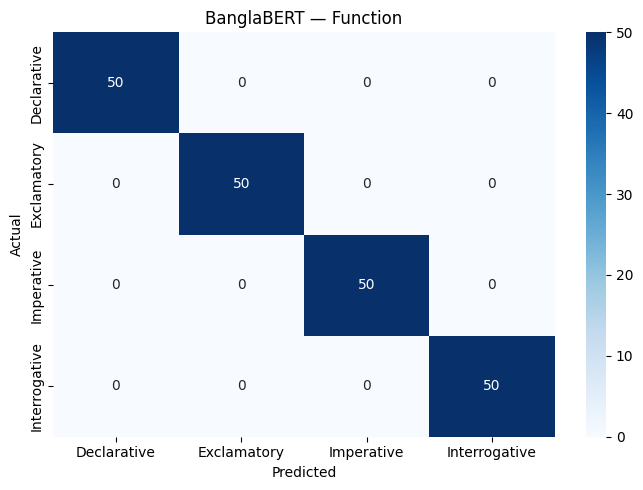

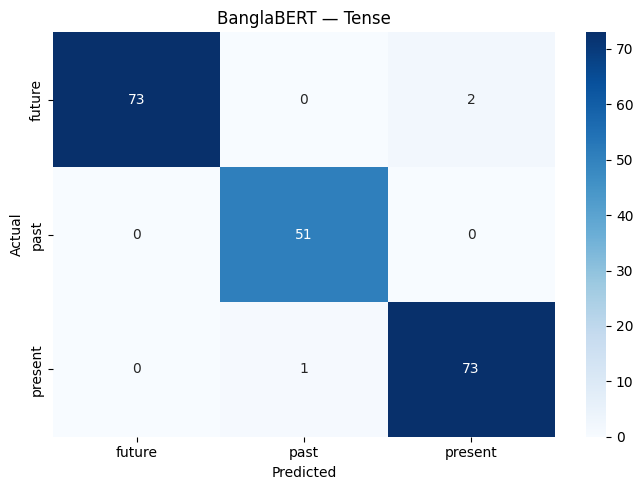

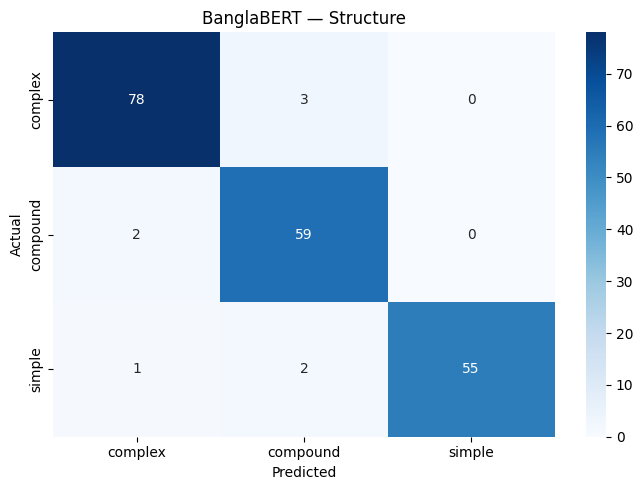

\n===========================================================================
TRAINING: XLM-RoBERTa | FacebookAI/xlm-roberta-base


config.json:   0%|          | 0.00/615 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.10M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.12GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] XLMRobertaModel LOAD REPORT from: FacebookAI/xlm-roberta-base
Key                       | Status     |  | 
--------------------------+------------+--+-
lm_head.layer_norm.bias   | UNEXPECTED |  | 
lm_head.bias              | UNEXPECTED |  | 
lm_head.dense.bias        | UNEXPECTED |  | 
lm_head.dense.weight      | UNEXPECTED |  | 
lm_head.layer_norm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Epoch 1/3 | loss=2.5572 | val avg Macro-F1=0.9238 Function=0.980 Tense=0.966 Structure=0.825
Epoch 2/3 | loss=0.5404 | val avg Macro-F1=0.9852 Function=0.995 Tense=0.986 Structure=0.975
Epoch 3/3 | loss=0.2066 | val avg Macro-F1=0.9868 Function=0.995 Tense=0.985 Structure=0.980
\n--- XLM-RoBERTa | TEST | Function ---
               precision    recall  f1-score   support

  Declarative     1.0000    1.0000    1.0000        50
  Exclamatory     1.0000    1.0000    1.0000        50
   Imperative     1.0000    1.0000    1.0000        50
Interrogative     1.0000    1.0000    1.0000        50

     accuracy                         1.0000       200
    macro avg     1.0000    1.0000    1.0000       200
 weighted avg     1.0000    1.0000    1.0000       200

\n--- XLM-RoBERTa | TEST | Tense ---
              precision    recall  f1-score   support

      future     1.0000    0.9733    0.9865        75
        past     0.9808    1.0000    0.9903        51
     present     0.9733    0.9865    0

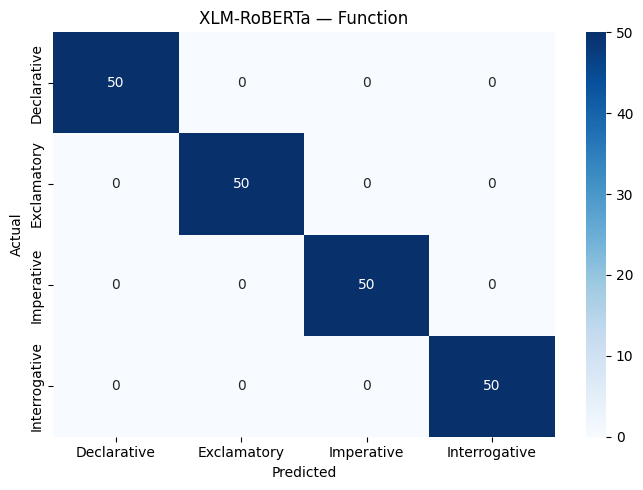

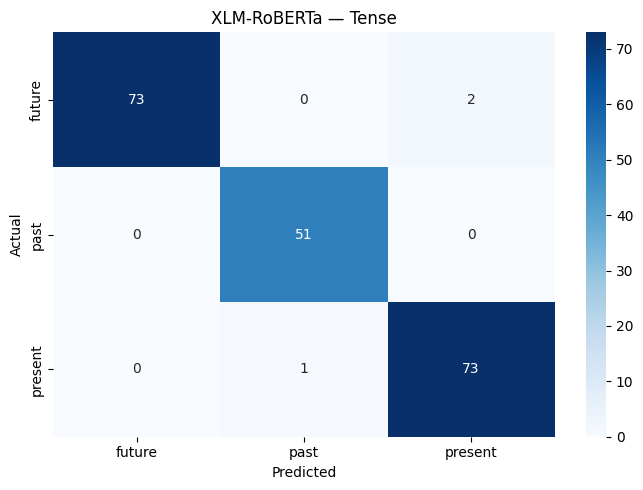

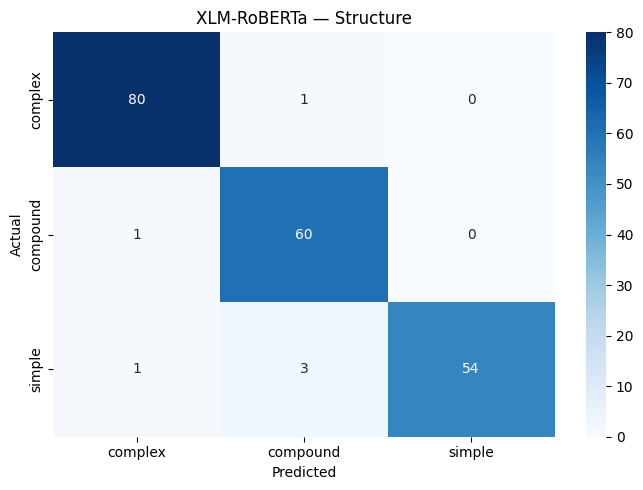

\n===========================================================================
TRAINING: MuRIL | google/muril-base-cased


config.json:   0%|          | 0.00/411 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/206 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/3.16M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/113 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  953MB            

... (2 outputs left out)

[transformers] BertModel LOAD REPORT from: google/muril-base-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.decoder.bias               | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


model.safetensors: reconstructing file:   0%|          |  0.00B /  953MB            

model.safetensors: downloading bytes:           |  0.00B            

Epoch 1/3 | loss=3.5201 | val avg Macro-F1=0.7180 Function=0.975 Tense=0.967 Structure=0.213
Epoch 2/3 | loss=3.3075 | val avg Macro-F1=0.8912 Function=0.985 Tense=0.995 Structure=0.693
Epoch 3/3 | loss=3.2352 | val avg Macro-F1=0.9505 Function=0.985 Tense=0.995 Structure=0.871
\n--- MuRIL | TEST | Function ---
               precision    recall  f1-score   support

  Declarative     1.0000    1.0000    1.0000        50
  Exclamatory     1.0000    1.0000    1.0000        50
   Imperative     1.0000    1.0000    1.0000        50
Interrogative     1.0000    1.0000    1.0000        50

     accuracy                         1.0000       200
    macro avg     1.0000    1.0000    1.0000       200
 weighted avg     1.0000    1.0000    1.0000       200

\n--- MuRIL | TEST | Tense ---
              precision    recall  f1-score   support

      future     1.0000    0.9867    0.9933        75
        past     0.9808    1.0000    0.9903        51
     present     0.9865    0.9865    0.9865       

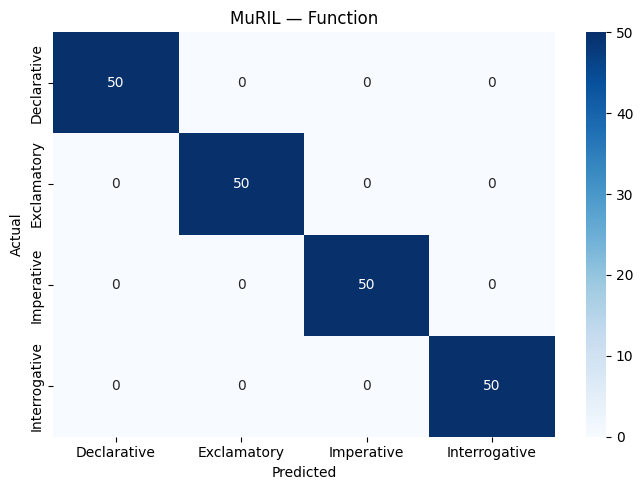

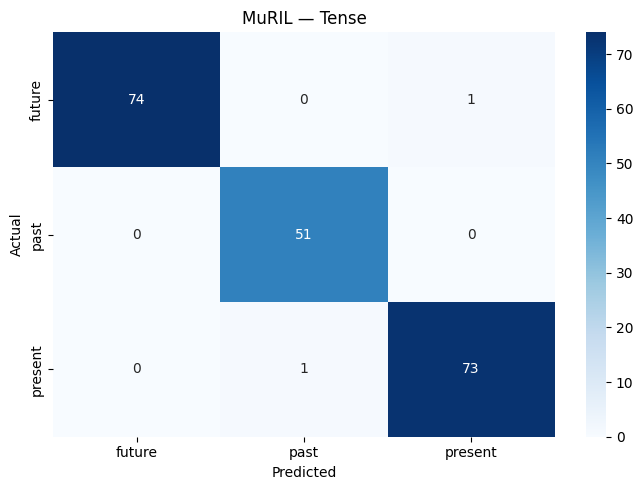

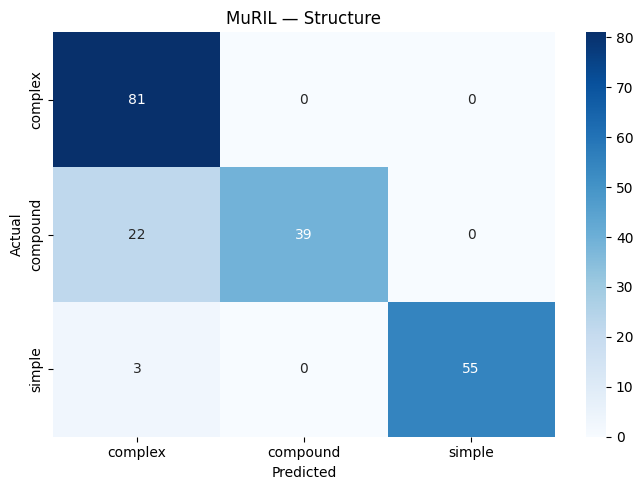

\n===========================================================================
TRAINING: IndicBERTv2 | ai4bharat/IndicBERTv2-MLM-only


config.json:   0%|          | 0.00/639 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/51.0 [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 7.75MB            

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

... (3 outputs left out)

[transformers] BertModel LOAD REPORT from: ai4bharat/IndicBERTv2-MLM-only
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.decoder.bias               | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


model.safetensors: reconstructing file:   0%|          |  0.00B / 1.12GB            

model.safetensors: downloading bytes:           |  0.00B            

Epoch 1/3 | loss=2.5935 | val avg Macro-F1=0.9127 Function=0.985 Tense=0.972 Structure=0.781
Epoch 2/3 | loss=0.4907 | val avg Macro-F1=0.9788 Function=0.985 Tense=0.991 Structure=0.961
Epoch 3/3 | loss=0.1758 | val avg Macro-F1=0.9852 Function=0.985 Tense=1.000 Structure=0.971
\n--- IndicBERTv2 | TEST | Function ---
               precision    recall  f1-score   support

  Declarative     1.0000    1.0000    1.0000        50
  Exclamatory     1.0000    1.0000    1.0000        50
   Imperative     1.0000    1.0000    1.0000        50
Interrogative     1.0000    1.0000    1.0000        50

     accuracy                         1.0000       200
    macro avg     1.0000    1.0000    1.0000       200
 weighted avg     1.0000    1.0000    1.0000       200

\n--- IndicBERTv2 | TEST | Tense ---
              precision    recall  f1-score   support

      future     1.0000    0.9733    0.9865        75
        past     0.9808    1.0000    0.9903        51
     present     0.9733    0.9865    0

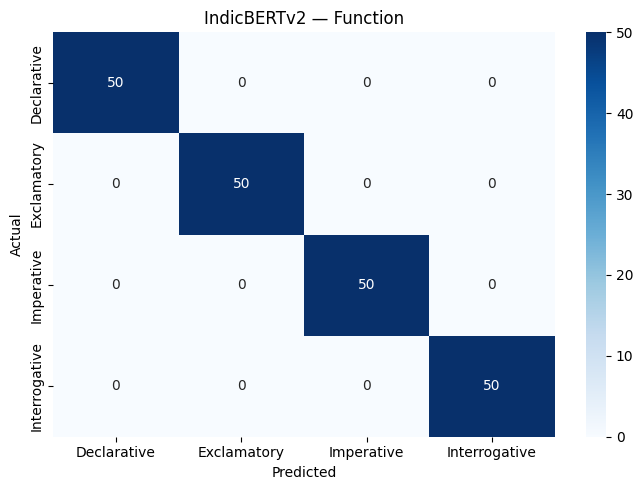

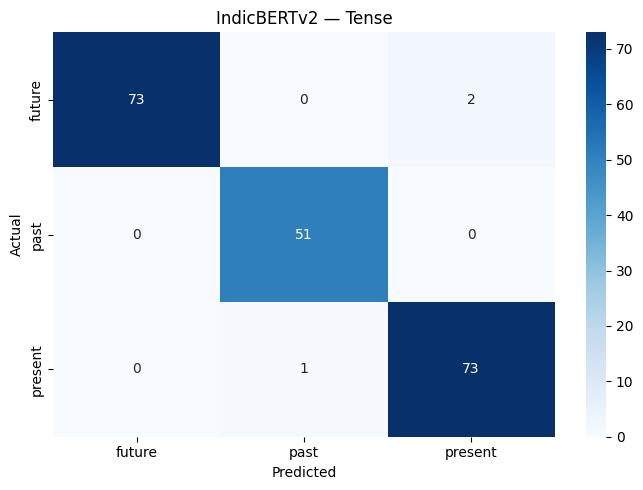

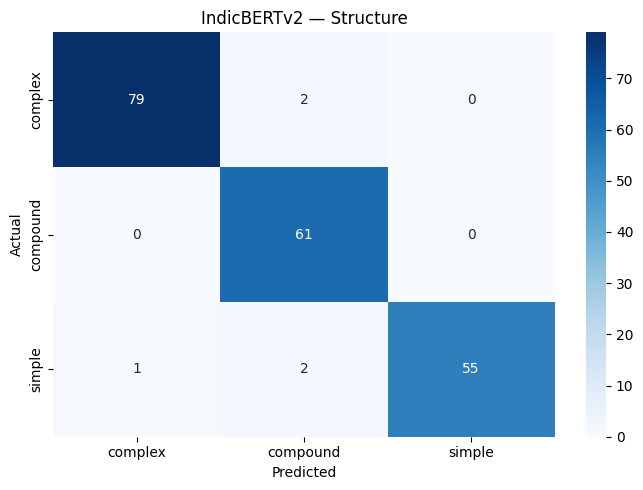

In [7]:
transformer_test_predictions = {}
transformer_test_actuals = {}

for model_label, model_name in MODEL_CONFIGS.items():
    print("\\n" + "=" * 75)
    print("TRAINING:", model_label, "|", model_name)
    print("=" * 75)

    tokenizer = AutoTokenizer.from_pretrained(model_name)
    train_loader = DataLoader(
        BanglaMultiTaskDataset(train_df, tokenizer),
        batch_size=BATCH_SIZE, shuffle=True, num_workers=0
    )
    val_loader = DataLoader(
        BanglaMultiTaskDataset(val_df, tokenizer),
        batch_size=BATCH_SIZE * 2, shuffle=False, num_workers=0
    )
    test_loader = DataLoader(
        BanglaMultiTaskDataset(test_df, tokenizer),
        batch_size=BATCH_SIZE * 2, shuffle=False, num_workers=0
    )

    model = MultiTaskTransformer(model_name).to(device)
    optimizer = torch.optim.AdamW(
        model.parameters(), lr=LEARNING_RATE, weight_decay=0.01
    )
    total_steps = int(np.ceil(len(train_loader) / GRAD_ACCUM)) * EPOCHS
    scheduler = get_linear_schedule_with_warmup(
        optimizer, int(0.1 * total_steps), total_steps
    )
    loss_fn = nn.CrossEntropyLoss()

    best_val = -1.0
    no_improve = 0
    best_path = f"{model_label.lower().replace('-', '_')}_best.pt"
    history = []

    for epoch in range(1, EPOCHS + 1):
        model.train()
        optimizer.zero_grad(set_to_none=True)
        running_loss = 0.0

        for step, batch in enumerate(train_loader, start=1):
            ids = batch["input_ids"].to(device)
            mask = batch["attention_mask"].to(device)
            outputs = model(ids, mask)
            loss = sum(
                loss_fn(outputs[task], batch[task].to(device))
                for task in TASKS
            ) / GRAD_ACCUM
            loss.backward()
            running_loss += loss.item() * GRAD_ACCUM

            if step % GRAD_ACCUM == 0 or step == len(train_loader):
                torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                optimizer.step()
                scheduler.step()
                optimizer.zero_grad(set_to_none=True)

        val_pred, val_true = predict_loader(model, val_loader)
        val_f1 = {
            task: f1_score(val_true[task], val_pred[task], average="macro", zero_division=0)
            for task in TASKS
        }
        avg_val_f1 = float(np.mean(list(val_f1.values())))
        history.append({
            "Model": model_label, "Epoch": epoch,
            "Train_Loss": running_loss / len(train_loader),
            "Val_Average_Macro_F1": avg_val_f1,
            **{f"Val_{task}_Macro_F1": val_f1[task] for task in TASKS}
        })
        print(
            f"Epoch {epoch}/{EPOCHS} | loss={running_loss/len(train_loader):.4f} "
            f"| val avg Macro-F1={avg_val_f1:.4f} "
            + " ".join(f"{t}={val_f1[t]:.3f}" for t in TASKS)
        )

        if avg_val_f1 > best_val:
            best_val = avg_val_f1
            no_improve = 0
            torch.save(model.state_dict(), best_path)
        else:
            no_improve += 1
            if no_improve >= PATIENCE:
                print("Early stopping.")
                break

    pd.DataFrame(history).to_csv(
        f"{model_label.lower().replace('-', '_')}_training_history.csv",
        index=False
    )

    # Evaluate the best validation checkpoint on the held-out test set.
    model.load_state_dict(torch.load(best_path, map_location=device))
    test_pred, test_true = predict_loader(model, test_loader)
    transformer_test_predictions[model_label] = test_pred
    transformer_test_actuals[model_label] = test_true
    all_results.extend(score_predictions(model_label, test_pred, test_true))

    # Save confusion matrices for each task.
    for task in TASKS:
        names = list(label_encoders[task].classes_)
        cm = confusion_matrix(
            test_true[task], test_pred[task],
            labels=list(range(len(names)))
        )
        plt.figure(figsize=(7, 5))
        sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                    xticklabels=names, yticklabels=names)
        plt.title(f"{model_label} — {task}")
        plt.xlabel("Predicted"); plt.ylabel("Actual")
        plt.tight_layout()
        plt.savefig(
            f"cm_{model_label.lower().replace('-', '_')}_{task.lower()}.png",
            dpi=160
        )
        plt.show()

    # Save tokenizer and model checkpoint for later prediction/interface work.
    save_dir = f"tokenizer_{model_label.lower().replace('-', '_')}"
    tokenizer.save_pretrained(save_dir)

    del model, tokenizer, optimizer, scheduler
    del train_loader, val_loader, test_loader
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()



## 4. Compare all five models

The table contains test-set scores for each task. Do not combine the three tasks into one ordinary classification accuracy; compare Function, Tense, and Structure separately.


In [8]:
results_df = pd.DataFrame(all_results)
results_df = results_df.sort_values(["Task", "Macro_F1"], ascending=[True, False])
display(results_df.round(4))
results_df.to_csv("five_model_comparison_results.csv", index=False)

print("\\nAverage task-level Macro-F1 (simple mean across the three tasks):")
display(
    results_df.groupby("Model")["Macro_F1"]
    .mean().sort_values(ascending=False).to_frame("Average_Task_Macro_F1").round(4)
)


,Model,Task,Accuracy,Precision_macro,Recall_macro,Macro_F1
3,BanglaBERT,Function,1.000,1.0000,1.0000,1.0000
6,XLM-RoBERTa,Function,1.000,1.0000,1.0000,1.0000
9,MuRIL,Function,1.000,1.0000,1.0000,1.0000
12,IndicBERTv2,Function,1.000,1.0000,1.0000,1.0000
0,Random Forest,Function,0.995,0.9951,0.9950,0.9950
14,IndicBERTv2,Structure,0.975,0.9753,0.9745,0.9744
8,XLM-RoBERTa,Structure,0.970,0.9710,0.9674,0.9686
2,Random Forest,Structure,0.960,0.9613,0.9608,0.9603
5,BanglaBERT,Structure,0.960,0.9616,0.9595,0.9601
11,MuRIL,Structure,0.875,0.9214,0.8625,0.8733


\nAverage task-level Macro-F1 (simple mean across the three tasks):


,Average_Task_Macro_F1
Model,
IndicBERTv2,0.9866
XLM-RoBERTa,0.9847
BanglaBERT,0.9819
Random Forest,0.9696
MuRIL,0.9544


## 5. Predict one new sentence with the selected transformer

This helper reloads a saved transformer checkpoint and returns predictions for all three tasks. The interface can be built around this function in the next step.


In [9]:
def load_transformer_for_prediction(model_label):
    if model_label not in MODEL_CONFIGS:
        raise ValueError(f"Choose one of: {list(MODEL_CONFIGS)}")
    model_name = MODEL_CONFIGS[model_label]
    tokenizer = AutoTokenizer.from_pretrained(
        f"tokenizer_{model_label.lower().replace('-', '_')}"
    )
    model = MultiTaskTransformer(model_name).to(device)
    checkpoint = f"{model_label.lower().replace('-', '_')}_best.pt"
    model.load_state_dict(torch.load(checkpoint, map_location=device))
    model.eval()
    return tokenizer, model

@torch.no_grad()
def predict_with_transformer(sentence, model_label="BanglaBERT"):
    tokenizer, model = load_transformer_for_prediction(model_label)
    enc = tokenizer(
        sentence, truncation=True, max_length=MAX_LEN,
        padding="max_length", return_tensors="pt"
    )
    ids = enc["input_ids"].to(device)
    mask = enc["attention_mask"].to(device)
    outputs = model(ids, mask)
    answer = {
        task: label_encoders[task].inverse_transform(
            [outputs[task].argmax(dim=-1).item()]
        )[0]
        for task in TASKS
    }
    del model, tokenizer
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    return answer

# Example:
print(predict_with_transformer("তুমি এবং আমি একসাথে খেলবো", "BanglaBERT"))


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] ElectraModel LOAD REPORT from: csebuetnlp/banglabert
Key                                               | Status     |  | 
--------------------------------------------------+------------+--+-
discriminator_predictions.dense.weight            | UNEXPECTED |  | 
discriminator_predictions.dense.bias              | UNEXPECTED |  | 
discriminator_predictions.dense_prediction.weight | UNEXPECTED |  | 
discriminator_predictions.dense_prediction.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


{'Function': 'Declarative', 'Tense': 'future', 'Structure': 'simple'}


## 6. Download the results and model files

This creates one ZIP file containing the result table, label maps, Random Forest models, transformer checkpoints, tokenizers, training histories, and confusion-matrix images. Keep this ZIP safe; it will be needed when we build the interface.


In [ ]:
import glob, zipfile
from google.colab import files

artifact_files = (
    glob.glob("*.joblib") +
    glob.glob("*_best.pt") +
    glob.glob("tokenizer_*/*") +
    glob.glob("*training_history.csv") +
    glob.glob("cm_*.png") +
    ["five_model_comparison_results.csv", "label_maps.json"]
)
artifact_files = [f for f in artifact_files if os.path.isfile(f)]
with zipfile.ZipFile("bangla_five_model_artifacts.zip", "w", zipfile.ZIP_DEFLATED) as zf:
    for path in artifact_files:
        zf.write(path)

print("Created bangla_five_model_artifacts.zip")
files.download("five_model_comparison_results.csv")
files.download("bangla_five_model_artifacts.zip")
